# 08 · The held-out exam

## Does the selected model hold up on speakers it has never heard?

Every earlier notebook used the 18 development speakers. Six speakers were
set aside by the speaker split, and no step so far has scored, tuned on or
plotted them. This notebook fits the recipe written down in
`model_choice.md` on all 1,080 development clips and scores the 360
held-out clips **once**. The exam is gated by `OPEN_HELD_OUT`. It was
switched on once, after `model_choice.md` was agreed; the saved
predictions are final, and a re-run loads them instead of fitting again.

**Inherits:** `model_choice.md`, `selection.json`, the flag operating
point fixed in `07_Flag_rate_and_threshold`, the 512-feature table and the
cached WavLM embeddings.
**Data:** 1,080 development clips to fit; the 360 held-out clips are scored
once, and only when the exam is open.
**Runtime:** about 10 s with saved outputs; about 20 min to rebuild the
rehearsal (`RUN_HEAVY = True`); about 6 min for the exam itself.
**Writes:** `outputs/tables/` (recipe check, held-out metrics, per-emotion
and per-speaker scores), `outputs/preds/` (held-out predictions) and
figure F15.

In [1]:
# Setup: shared helpers, paths, and the two switches of this notebook.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import f1_score
HERE = Path.cwd()
SHARED = next(p / "shared" for p in [HERE, *HERE.parents]
              if (p / "shared" / "audio_utils.py").exists())
sys.path.insert(0, str(SHARED))
import audio_utils as U
import cv_harness as H
import speaker_split as S

# False: load the saved recipe check and, if the exam has been run,
# its saved predictions ([cache hit]). True: rebuild them.
RUN_HEAVY = False

# False: the held-out speakers stay closed; only development speakers
# are used. True: fit on all development clips, score the held-out
# clips once. Set it only after `model_choice.md` has been agreed.
OPEN_HELD_OUT = True
SUB = U.submission_root()
MODELLING = SUB / "Modelling" / "outputs"
EVAL_OUT = SUB / "Evaluation" / "outputs"
OUT = SUB / "Evaluation" / "outputs"
TABLES, FIGS, PREDS_OUT = OUT / "tables", OUT / "figures", OUT / "preds"
for d in (TABLES, FIGS, PREDS_OUT):
    d.mkdir(parents=True, exist_ok=True)
EMB_PATH = SUB / "cache" / "ssl_embeddings" / "emb_wavlm.npy"
EMOS = list(U.EMOTION_ORDER)
SUMMARY = []


def record(h, claim, verdict, evidence, decision):
    """Store one hypothesis result and print its verdict."""
    SUMMARY.append({
        "H": h, "hypothesis": claim, "verdict": verdict,
        "evidence": evidence, "so we": decision,
    })
    print(f"\n{h} · {claim}\n    verdict: {verdict.upper()}")


index = U.load_index()
dev = S.dev_mask(index)
S.assert_no_test_speakers(index.loc[dev, "filepath"], "dev mask")
print(f"dev clips: {int(dev.sum())}  held out: {int((~dev).sum())}  "
      f"exam open: {OPEN_HELD_OUT}")


dev clips: 1080  held out: 360  exam open: True


## 1 · The recipe, and a rehearsal on development speakers

`model_choice.md` fixes two heads. The **selected** head is a standardised
logistic regression on one hidden layer of the frozen WavLM encoder; the
layer and the regularisation C are picked together by inner speaker-grouped
CV. The **reference** head is the same kind of logistic regression on the
512 acoustic features. Both are fitted with `shared/cv_harness.fit_tuned`.

In [2]:
# The two heads. Inputs are arrays already restricted to the training
# clips; nothing here can see a clip that is not passed in.
LAYERS = list(range(13))
C_WAVLM = [0.01, 0.1, 1.0]
C_CLASSICAL = [0.01, 0.03, 0.1, 0.3, 1.0]


def fit_wavlm_head(emb, y, groups):
    """Fit the selected head: pick the layer and C by inner CV.

    Parameters
    ----------
    emb : numpy.ndarray
        Clip embeddings, shape (n_clips, 13 layers, 768 units).
    y : numpy.ndarray
        Emotion labels of the training clips.
    groups : numpy.ndarray
        Speaker id of each training clip (inner folds never split a
        speaker).

    Returns
    -------
    pipe, layer, params, inner_macro_f1
        Fitted pipeline, chosen layer, chosen C, inner macro-F1.
    """
    est = LogisticRegression(max_iter=5000, class_weight="balanced")
    best = None
    for layer in LAYERS:
        pipe, params, inner = H.fit_tuned(
            est, emb[:, layer, :].astype(np.float64), y, groups,
            param_grid={"C": C_WAVLM})
        if best is None or inner > best[0]:
            best = (inner, layer, params, pipe)
    inner, layer, params, pipe = best
    return pipe, layer, params, inner


def fit_classical_head(X, y, groups):
    """Fit the reference head on the 512 acoustic features.

    Returns
    -------
    pipe, params, inner_macro_f1
    """
    est = LogisticRegression(max_iter=5000, class_weight="balanced")
    return H.fit_tuned(est, X, y, groups, param_grid={"C": C_CLASSICAL})


# Whole-table arrays, aligned to the label index. Rows are selected by
# mask before any fitting, so training never sees a held-out row.
feats = pd.read_parquet(H.FEATURES_PATH)
assert (feats["filepath"].values == index["filepath"].values).all()
FEATURE_COLS = [c for c in feats.columns
                if c not in ("filepath", "emotion")]
X_ALL = np.nan_to_num(feats[FEATURE_COLS].to_numpy(dtype=np.float64),
                      nan=0.0, posinf=0.0, neginf=0.0)
def load_wavlm_embeddings():
    """Load WavLM embeddings only when a rebuild needs them.

    Returns
    -------
    numpy.ndarray
        Shape (1440, 13, 768) float32.
    """
    if not EMB_PATH.exists():
        raise FileNotFoundError(
            f"Missing {EMB_PATH.relative_to(SUB)}. Rebuild with "
            "RUN_HEAVY = True in Modelling/05_Pretrained_encoders "
            "(embedding extraction cell), then re-run this notebook."
        )
    E = np.load(EMB_PATH)
    assert E.shape[:2] == (len(index), len(LAYERS))
    return E


E_ALL = None  # loaded lazily when a rebuild is required
Y_ALL = index["emotion"].to_numpy(dtype=object)
G_ALL = index["speaker"].to_numpy(dtype=np.int64)
FP_ALL = index["filepath"].to_numpy(dtype=object)
emb_note = "lazy (not loaded)" if E_ALL is None else E_ALL.shape
print(f"features {X_ALL.shape}; WavLM embeddings {emb_note}")

features (1440, 512); WavLM embeddings lazy (not loaded)


In [3]:
# Rehearsal: refit both heads on the training part of each development
# fold and compare with the predictions saved by the modelling
# notebooks. If the recipe were wrong, the exam would be meaningless.
CHECK_PATH = TABLES / "recipe_check.csv"


def rehearse() -> pd.DataFrame:
    """Refit both heads fold by fold and compare with saved files."""
    global E_ALL
    if E_ALL is None:
        E_ALL = load_wavlm_embeddings()
    idx = np.flatnonzero(dev)
    y, g = Y_ALL[idx], G_ALL[idx]
    folds = S.get_dev_folds().split(np.zeros(len(y)), y, groups=g)
    rows = []
    for k, (tr, va) in enumerate(folds):
        tr, va = idx[tr], idx[va]
        S.assert_no_test_speakers(FP_ALL[tr], f"rehearsal fold {k} train")
        S.assert_no_test_speakers(FP_ALL[va], f"rehearsal fold {k} score")
        pw, layer, prm, inner = fit_wavlm_head(
            E_ALL[tr], Y_ALL[tr], G_ALL[tr])
        proba_w = pw.predict_proba(
            E_ALL[va][:, layer, :].astype(np.float64))
        pc, prc, innerc = fit_classical_head(
            X_ALL[tr], Y_ALL[tr], G_ALL[tr])
        proba_c = pc.predict_proba(X_ALL[va])
        for name, proba, classes, info in (
                ("wavlm", proba_w, pw.classes_,
                 {"layer": layer, "C": prm["C"], "inner": inner}),
                ("logreg", proba_c, pc.classes_,
                 {"layer": np.nan, "C": prc["C"], "inner": innerc})):
            saved = pd.read_csv(
                MODELLING / "preds" / f"{name}_grouped_fold{k}.csv")
            assert (saved["filepath"].values == FP_ALL[va]).all()
            pred = np.array(classes)[proba.argmax(axis=1)]
            rows.append({
                "model": name, "fold": k, **info,
                "macro_f1": f1_score(Y_ALL[va], pred, average="macro",
                                     labels=EMOS, zero_division=0),
                "saved_macro_f1": f1_score(
                    saved["true_emotion"], saved["pred_emotion"],
                    average="macro", labels=EMOS, zero_division=0),
                "prediction_agreement": float(
                    (pred == saved["pred_emotion"].values).mean()),
            })
        print(f"  rehearsal fold {k} done", flush=True)
    return pd.DataFrame(rows)


if CHECK_PATH.exists() and not RUN_HEAVY:
    check = pd.read_csv(CHECK_PATH)
    print(f"[cache hit] {CHECK_PATH.relative_to(SUB)}")
else:
    check = rehearse()
    check.round(6).to_csv(CHECK_PATH, index=False)
display(check.round(4))
worst = check["prediction_agreement"].min()
assert worst >= 0.99, "recipe does not reproduce the saved predictions"
print(f"[ok] the recipe reproduces the saved development predictions: "
      f"lowest agreement {100 * worst:.1f}% over "
      f"{len(check)} fitted folds")

[cache hit] Evaluation/outputs/tables/recipe_check.csv


,model,fold,layer,C,inner,macro_f1,saved_macro_f1,prediction_agreement
0,wavlm,0,6.0,0.10,0.7201,0.7824,0.7824,1.0000
1,logreg,0,NaN,0.10,0.5043,0.5034,0.5034,1.0000
2,wavlm,1,6.0,0.01,0.7518,0.7577,0.7577,1.0000
3,logreg,1,NaN,0.10,0.5239,0.4812,0.4812,1.0000
4,wavlm,2,6.0,0.01,0.7332,0.7985,0.7985,1.0000
5,logreg,2,NaN,0.03,0.4858,0.5382,0.5382,1.0000
6,wavlm,3,6.0,1.00,0.7778,0.6647,0.6647,1.0000
7,logreg,3,NaN,0.03,0.5093,0.4635,0.4580,0.9944
8,wavlm,4,6.0,0.10,0.7238,0.7695,0.7695,1.0000
9,logreg,4,NaN,0.01,0.4948,0.5901,0.5901,1.0000


[ok] the recipe reproduces the saved development predictions: lowest agreement 99.4% over 12 fitted folds


## 2 · The exam

With the switch closed, the cell below only says so. With the switch open,
it fits both heads on all 1,080 development clips, scores the 360 held-out
clips once, and stores the predictions; a later run loads them instead of
fitting again.

In [4]:
# Choose the rows. The exam fits on development speakers only and
# scores the held-out speakers, checked against the frozen split.
split = S.load_frozen_split()
train_mask = dev
held_mask = ~dev
if OPEN_HELD_OUT:
    assert set(G_ALL[held_mask]) == set(split["test_speakers"])
    assert int(held_mask.sum()) == split["n_test_clips"]
train_idx, held_idx = np.flatnonzero(train_mask), np.flatnonzero(held_mask)


def run_exam(tag: str) -> dict:
    """Fit both heads on the training rows and score the held rows once.

    Parameters
    ----------
    tag : str
        Suffix of the prediction files written to ``outputs/preds/``.

    Returns
    -------
    dict
        Predictions of both heads and the settings each one chose.
    """
    global E_ALL
    S.assert_no_test_speakers(FP_ALL[train_idx], "training rows")
    paths = {m: PREDS_OUT / f"{m}_{tag}.csv" for m in ("wavlm", "logreg")}
    fit_path = TABLES / f"exam_fit_{tag}.json"
    saved_ready = (
        all(p.exists() for p in paths.values()) and fit_path.exists()
    )
    # The held-out result is final. Never overwrite it.
    if saved_ready and not RUN_HEAVY:
        print("[cache hit] saved held-out predictions")
        fit = json.loads(fit_path.read_text())
    elif saved_ready and RUN_HEAVY:
        # Refit to a temporary path and compare; keep the saved files.
        print("[RUN_HEAVY] refitting exam to a temp path for comparison; "
              "saved held-out preds stay unchanged")
        if E_ALL is None:
            E_ALL = load_wavlm_embeddings()
        import tempfile
        tmp = Path(tempfile.mkdtemp(prefix="exam_refit_"))
        pw, layer, prm, inner = fit_wavlm_head(
            E_ALL[train_idx], Y_ALL[train_idx], G_ALL[train_idx])
        H.save_preds(tmp / "wavlm.csv", FP_ALL[held_idx], Y_ALL[held_idx],
                     pw.predict_proba(
                         E_ALL[held_idx][:, layer, :].astype(np.float64)),
                     pw.classes_)
        pc, prc, innerc = fit_classical_head(
            X_ALL[train_idx], Y_ALL[train_idx], G_ALL[train_idx])
        H.save_preds(tmp / "logreg.csv", FP_ALL[held_idx], Y_ALL[held_idx],
                     pc.predict_proba(X_ALL[held_idx]), pc.classes_)
        for m in ("wavlm", "logreg"):
            a = pd.read_csv(paths[m])
            b = pd.read_csv(tmp / f"{m}.csv")
            agree = float((a["pred_emotion"] == b["pred_emotion"]).mean())
            print(f"  {m} temp vs saved pred agreement: {agree:.4f}")
        fit = json.loads(fit_path.read_text())
    elif not saved_ready:
        if E_ALL is None:
            E_ALL = load_wavlm_embeddings()
        pw, layer, prm, inner = fit_wavlm_head(
            E_ALL[train_idx], Y_ALL[train_idx], G_ALL[train_idx])
        H.save_preds(paths["wavlm"], FP_ALL[held_idx], Y_ALL[held_idx],
                     pw.predict_proba(
                         E_ALL[held_idx][:, layer, :].astype(np.float64)),
                     pw.classes_)
        pc, prc, innerc = fit_classical_head(
            X_ALL[train_idx], Y_ALL[train_idx], G_ALL[train_idx])
        H.save_preds(paths["logreg"], FP_ALL[held_idx], Y_ALL[held_idx],
                     pc.predict_proba(X_ALL[held_idx]), pc.classes_)
        fit = {"wavlm": {"layer": int(layer), "C": prm["C"],
                         "inner_macro_f1": round(inner, 4)},
               "logreg": {"C": prc["C"],
                          "inner_macro_f1": round(innerc, 4)},
               "n_train": int(len(train_idx)), "n_scored": int(
                   len(held_idx))}
        fit_path.write_text(json.dumps(fit, indent=2))
    else:
        raise RuntimeError("unreachable exam branch")
    out = {m: pd.read_csv(p) for m, p in paths.items()}
    for m, df in out.items():
        df["speaker"] = df["filepath"].map(S.speaker_of)
        df["correct"] = df["true_emotion"] == df["pred_emotion"]
    return {"preds": out, "fit": fit}


if OPEN_HELD_OUT:
    EXAM = run_exam("heldout")
    print(json.dumps(EXAM["fit"], indent=2))
    print({m: len(df) for m, df in EXAM["preds"].items()},
          "clips scored")
else:
    EXAM = None
    print("[closed] the held-out speakers have not been opened; "
          "every result below is pending.")

[cache hit] saved held-out predictions
{
  "wavlm": {
    "layer": 5,
    "C": 1.0,
    "inner_macro_f1": 0.7476
  },
  "logreg": {
    "C": 0.01,
    "inner_macro_f1": 0.5058
  },
  "n_train": 1080,
  "n_scored": 360
}
{'wavlm': 360, 'logreg': 360} clips scored


In [5]:
# Metrics on the scored clips, and the reference points.
def macro_f1(df: pd.DataFrame) -> float:
    """Macro-F1 (unitless, 0-1) of a prediction table."""
    return f1_score(df["true_emotion"], df["pred_emotion"],
                    average="macro", labels=EMOS, zero_division=0)


def per_speaker(df: pd.DataFrame) -> pd.Series:
    """Macro-F1 of each speaker's clips."""
    return pd.Series({s: macro_f1(g) for s, g in df.groupby("speaker")})


def speaker_interval(df: pd.DataFrame, n_boot: int = 2000,
                     seed: int = 42):
    """95% interval of macro-F1, resampling speakers with replacement."""
    rng = np.random.default_rng(seed)
    parts = {s: g for s, g in df.groupby("speaker")}
    spk = np.array(list(parts))
    vals = [macro_f1(pd.concat([parts[s] for s in
                                rng.choice(spk, len(spk))]))
            for _ in range(n_boot)]
    return tuple(np.percentile(vals, [2.5, 97.5]))


if EXAM is not None:
    P = EXAM["preds"]
    # Constant "always the most common class" reference, as in the
    # modelling notebooks (calm).
    base = pd.read_csv(MODELLING / "tables" / "baselines_rows.csv")
    recall = json.loads(
        base.loc[base["model"] == "majority",
                 "per_class_recall_json"].iloc[0])
    majority = max(recall, key=recall.get)
    maj = P["wavlm"].assign(pred_emotion=majority)
    rows = []
    for name, df in (("majority", maj), ("logreg", P["logreg"]),
                     ("wavlm", P["wavlm"])):
        rows.append({
            "model": name, "macro_f1": macro_f1(df),
            "accuracy": accuracy_score(df["true_emotion"],
                                       df["pred_emotion"]),
            "balanced_accuracy": balanced_accuracy_score(
                df["true_emotion"], df["pred_emotion"])})
    M = pd.DataFrame(rows).set_index("model")
    lo_w, hi_w = speaker_interval(P["wavlm"])
    M.loc["wavlm", "ci_low"], M.loc["wavlm", "ci_high"] = lo_w, hi_w
    M.round(4).to_csv(TABLES / "heldout_metrics.csv")
    rec = pd.DataFrame({
        m: P[m].groupby("true_emotion")["correct"].mean().reindex(EMOS)
        for m in ("logreg", "wavlm")}) * 100
    rec.round(1).to_csv(TABLES / "heldout_recall_by_emotion.csv")
    spk = pd.DataFrame({m: per_speaker(P[m])
                        for m in ("logreg", "wavlm")})
    spk.round(4).to_csv(TABLES / "heldout_macro_f1_by_speaker.csv")
    display(M.round(4))
    display(spk.round(3))
    print(f"majority-class reference predicts {majority!r}")
else:
    print("[closed] no held-out metrics yet")

,macro_f1,accuracy,balanced_accuracy,ci_low,ci_high
model,,,,,
majority,0.0294,0.1333,0.1250,NaN,NaN
logreg,0.5775,0.5778,0.5781,NaN,NaN
wavlm,0.7596,0.7611,0.7578,0.6527,0.8519


,logreg,wavlm
1,0.650,0.801
4,0.576,0.731
8,0.846,0.944
9,0.344,0.529
20,0.435,0.677
21,0.486,0.806


majority-class reference predicts 'calm'


### H37 · The selected model keeps its development performance on unseen speakers

**Why it matters:** the development estimate came from speakers that
took turns being held out, but the model choice was made looking at them.
Only speakers nobody has looked at can say whether the number transfers.

In [6]:
# Bar fixed in model_choice.md: inside the development band
# (mean +- 1 sd of the selected model's six grouped folds).
sel = json.loads((MODELLING / "tables" / "selection.json").read_text())
lo = sel["selected_macro_f1"] - sel["selected_sd"]
hi = sel["selected_macro_f1"] + sel["selected_sd"]
CLAIM37 = ("The selected model keeps its development performance on "
           "unseen speakers")
if EXAM is None:
    record("H37", CLAIM37, "pending", "held-out speakers closed",
           "open the exam once the team agrees `model_choice.md`")
else:
    val = float(M.loc["wavlm", "macro_f1"])
    ci = (float(M.loc["wavlm", "ci_low"]), float(M.loc["wavlm", "ci_high"]))
    print(f"held-out macro-F1 {val:.4f}; 95% interval (speakers "
          f"resampled) {ci[0]:.4f} to {ci[1]:.4f}")
    print(f"development band {lo:.4f} to {hi:.4f}")
    verdict = "supported" if val >= lo else "not supported"
    place = ("above" if val > hi else "inside" if val >= lo
             else "below")
    record("H37", CLAIM37, verdict,
           f"held-out macro-F1 {val:.4f} ({place} the development band "
           f"{lo:.4f} to {hi:.4f})",
           "quote the held-out number next to the development number")


held-out macro-F1 0.7596; 95% interval (speakers resampled) 0.6527 to 0.8519
development band 0.7065 to 0.8005

H37 · The selected model keeps its development performance on unseen speakers
    verdict: SUPPORTED


**Verdict: supported. [EVIDENCE]** The held-out macro-F1 is 0.7596, inside the development band of 0.7065 to 0.8005. The development estimate transfers to voices nobody looked at. Resampling the six speakers gives a 95% interval of 0.6527 to 0.8519: wide, because six speakers are a small sample.

**So we** quote the held-out number next to the development number, always with its interval.

### H38 · The gain of WavLM over the classical rung holds on unseen speakers

**Why it matters:** the case for the frozen encoder rests on it beating
the simple model for voices it was not tuned on.

In [7]:
CLAIM38 = ("The gain of WavLM over the classical rung holds on unseen "
           "speakers")
if EXAM is None:
    record("H38", CLAIM38, "pending", "held-out speakers closed",
           "open the exam once the team agrees `model_choice.md`")
else:
    n_spk = len(spk)
    need = int(np.ceil(5 / 6 * n_spk))  # 5 of 6 speakers
    wins = int((spk["wavlm"] > spk["logreg"]).sum())
    gain = float(M.loc["wavlm", "macro_f1"] - M.loc["logreg", "macro_f1"])
    print(f"held-out macro-F1: wavlm {M.loc['wavlm', 'macro_f1']:.4f}, "
          f"logreg {M.loc['logreg', 'macro_f1']:.4f} (gain {gain:+.4f})")
    print(f"speakers where wavlm is ahead: {wins} of {n_spk} "
          f"(bar: {need})")
    verdict = ("supported" if gain > 0 and wins >= need else
               "partly supported" if gain > 0 else "not supported")
    record("H38", CLAIM38, verdict,
           f"gain {gain:+.4f} macro-F1; ahead on {wins} of {n_spk} "
           f"speakers",
           "state the encoder's gain as measured on unseen speakers")


held-out macro-F1: wavlm 0.7596, logreg 0.5775 (gain +0.1822)
speakers where wavlm is ahead: 6 of 6 (bar: 5)

H38 · The gain of WavLM over the classical rung holds on unseen speakers
    verdict: SUPPORTED


**Verdict: supported. [EVIDENCE]** On the held-out speakers WavLM scores 0.7596 against 0.5775 for logistic regression (gain +0.1822) and is ahead for 6 of 6 speakers, above the bar of 5. The encoder's advantage is not an artefact of tuning on the development voices.

**So we** state the encoder's gain as measured on unseen speakers, with the speaker count beside it.

### H39 · The flag rule fixed on development speakers keeps its behaviour on unseen speakers

**Why it matters:** a threshold is a promise about how many clips a
reviewer will read and how many negative clips they will catch. It is only
a promise if it transfers without re-tuning.

In [8]:
# The threshold was fixed in 07 on development speakers only. Bars from
# model_choice.md: flag rate between 25% and 35%, and capture no more
# than 10 points below the development capture.
op = json.loads(
    (EVAL_OUT / "tables" / "flag_operating_point.json").read_text())
NEG = op["negative_emotions"]
CLAIM39 = ("The flag rule fixed on development speakers keeps its "
           "behaviour on unseen speakers")
if EXAM is None:
    record("H39", CLAIM39, "pending", "held-out speakers closed",
           "open the exam once the team agrees `model_choice.md`")
else:
    df = P["wavlm"]
    flagged = (df["pred_emotion"].isin(NEG)
               & (df["pred_confidence"] >= op["threshold"]))
    true_neg = df["true_emotion"].isin(NEG)
    rate = float(flagged.mean())
    capture = float((flagged & true_neg).sum() / true_neg.sum())
    precision = float((flagged & true_neg).sum() / max(flagged.sum(), 1))
    floor = op["dev_capture"] - 0.10
    print(f"threshold {op['threshold']} (fixed on development speakers)")
    print(f"held-out flag rate {100 * rate:.1f}% (development "
          f"{100 * op['flag_rate']:.0f}%; bar 25% to 35%)")
    print(f"held-out capture {100 * capture:.1f}% (development "
          f"{100 * op['dev_capture']:.1f}%; bar at least "
          f"{100 * floor:.1f}%)")
    print(f"held-out precision {100 * precision:.1f}% (development "
          f"{100 * op['dev_precision']:.1f}%)")
    ok = [0.25 <= rate <= 0.35, capture >= floor]
    verdict = ("supported" if all(ok) else
               "partly supported" if any(ok) else "not supported")
    record("H39", CLAIM39, verdict,
           f"flag rate {100 * rate:.1f}%, capture {100 * capture:.1f}%, "
           f"precision {100 * precision:.1f}% at threshold "
           f"{op['threshold']}",
           "quote the flag rule with its held-out flag rate and capture")


threshold 0.827 (fixed on development speakers)
held-out flag rate 39.2% (development 30%; bar 25% to 35%)
held-out capture 70.3% (development 54.2%; bar at least 44.2%)
held-out precision 95.7% (development 96.3%)

H39 · The flag rule fixed on development speakers keeps its behaviour on unseen speakers
    verdict: PARTLY SUPPORTED


**Verdict: partly supported. [EVIDENCE]** At the fixed threshold of 0.827 the held-out flag rate is 39.2%, outside the 25% to 35% bar (development 30%). Capture is 70.3%, well above its floor of 44.2% (development 54.2%), and precision holds at 95.7% (development 96.3%). More clips cross the threshold on these six voices: the reviewer's workload grows, and the quality of the queue does not fall.

**So we** quote the flag rule with its held-out flag rate and capture, and keep the threshold unchanged: re-tuning it on the held-out speakers would use the exam twice.

saved Evaluation/outputs/figures/F15_heldout_wavlm.png


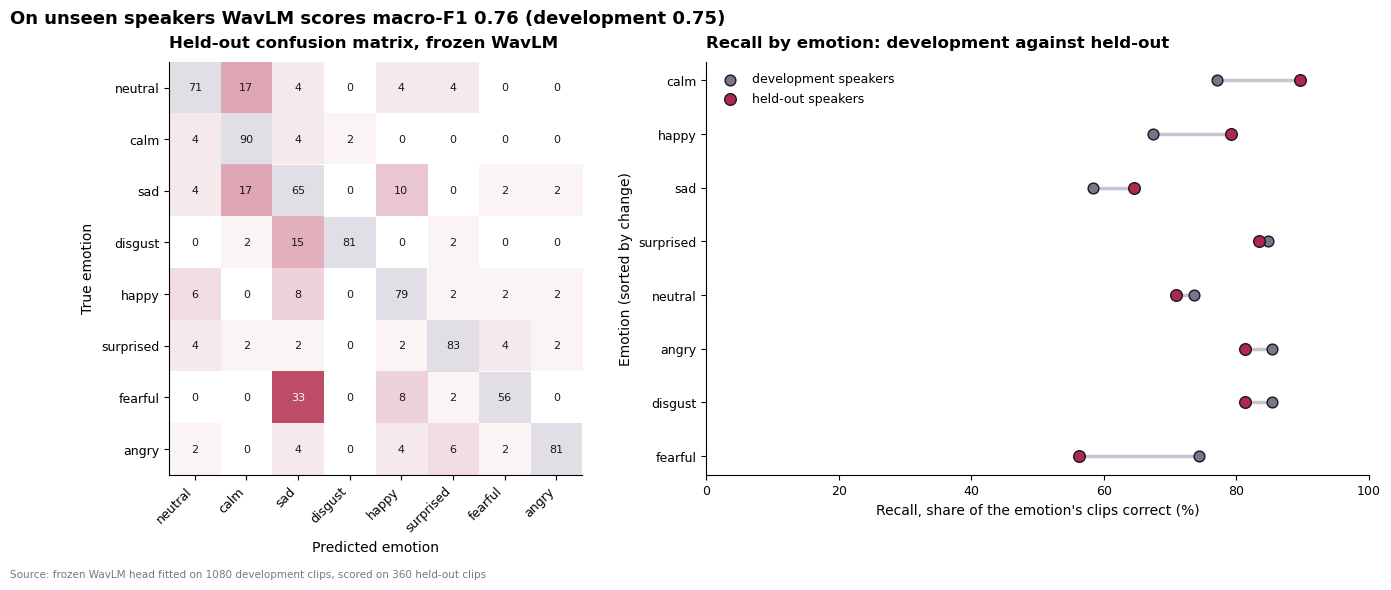

In [9]:
# F15: held-out confusion matrix of the selected model (left) and
# recall by emotion, development against held-out (right).
if EXAM is None:
    print("[closed] no held-out figure yet")
else:
    from matplotlib.colors import LinearSegmentedColormap
    from matplotlib.patches import Rectangle
    df = P["wavlm"]
    cm = (pd.crosstab(df["true_emotion"], df["pred_emotion"])
          .reindex(index=EMOS, columns=EMOS, fill_value=0))
    frac = cm.div(cm.sum(axis=1), axis=0).values * 100
    dev_rec = pd.read_csv(EVAL_OUT / "tables"
                          / "per_emotion_recall_by_rung.csv",
                          index_col="emotion")["wavlm"].reindex(EMOS)
    held_rec = rec["wavlm"].reindex(EMOS)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6),
                                 gridspec_kw={"width_ratios": [1.1, 1]})
    cmap = LinearSegmentedColormap.from_list("err", ["#FFFFFF", U.ACCENT])
    a1.imshow(np.where(np.eye(8, dtype=bool), np.nan, frac),
              cmap=cmap, vmin=0, vmax=40)
    for i in range(8):
        a1.add_patch(Rectangle((i - .5, i - .5), 1, 1, color=U.MUTED,
                               alpha=.55, lw=0))
        for j in range(8):
            a1.text(j, i, f"{frac[i, j]:.0f}", ha="center", va="center",
                    fontsize=8,
                    color=U.INK if i == j or frac[i, j] < 25 else "w")
    a1.set_xticks(range(8), EMOS, rotation=45, ha="right")
    a1.set_yticks(range(8), EMOS)
    U.finish_axes(a1, "Held-out confusion matrix, frozen WavLM",
                  "Predicted emotion", "True emotion", source="")
    order = list((held_rec - dev_rec).sort_values().index)
    for y_, e in enumerate(order):
        a2.plot([dev_rec[e], held_rec[e]], [y_, y_], color=U.MUTED,
                lw=2.5, zorder=1)
    a2.scatter(dev_rec[order], range(8), s=60, color=U.GREY,
               edgecolor=U.INK, zorder=3, label="development speakers")
    a2.scatter(held_rec[order], range(8), s=70, color=U.ACCENT,
               edgecolor=U.INK, zorder=4, label="held-out speakers")
    a2.set_yticks(range(8), order)
    a2.set_xlim(0, 100)
    U.finish_axes(a2, "Recall by emotion: development against held-out",
                  "Recall, share of the emotion's clips correct (%)",
                  "Emotion (sorted by change)",
                  source=(f"Source: frozen WavLM head fitted on "
                          f"{int(len(train_idx))} development clips, "
                          f"scored on {int(len(held_idx))} held-out "
                          f"clips"),
                  legend=True)
    fig.suptitle(
        f"On unseen speakers WavLM scores macro-F1 "
        f"{M.loc['wavlm', 'macro_f1']:.2f} "
        f"(development {sel['selected_macro_f1']:.2f})",
        x=0.01, y=1.02, ha="left", fontsize=13, fontweight="600")
    U.save_figure(fig, "F15_heldout_wavlm.png", out_dir=FIGS)
    plt.show()

---
## Summary

In [10]:
summary = pd.DataFrame(SUMMARY).set_index("H")
with pd.option_context("display.max_colwidth", 88):
    display(summary)
summary.to_csv(TABLES / "summary_08.csv")

,hypothesis,verdict,evidence,so we
H,,,,
H37,The selected model keeps its development performance on unseen speakers,supported,held-out macro-F1 0.7596 (inside the development band 0.7065 to 0.8005),quote the held-out number next to the development number
H38,The gain of WavLM over the classical rung holds on unseen speakers,supported,gain +0.1822 macro-F1; ahead on 6 of 6 speakers,state the encoder's gain as measured on unseen speakers
H39,The flag rule fixed on development speakers keeps its behaviour on unseen speakers,partly supported,"flag rate 39.2%, capture 70.3%, precision 95.7% at threshold 0.827",quote the flag rule with its held-out flag rate and capture


**Hands on:** the held-out macro-F1, its interval and the flag behaviour above are the figures every document quotes. The held-out speakers have now been opened once; no later step refits or re-tunes on them.